# Perbandingan Deep Learning — CNN 1D Reguler vs Tabular Conformer

Notebook ini melatih **CNN 1D reguler** sebagai pembanding deep learning untuk model utama Tabular Conformer.

Protokol diselaraskan dengan notebook `SHAP_XAI_conformer_v2.ipynb`:
- Dataset: `merge_DocLab_balanced.csv`.
- Fitur dan urutan fitur: sama dengan Conformer (13 fitur).
- Target: `NM_UNIT` (kelas 0–3).
- Split stratified: 70% train, 15% validation, 15% test dengan `random_state=42`.
- `StandardScaler` di-fit pada train saja.
- Early stopping berdasarkan macro-F1 validation dan test set hanya digunakan untuk evaluasi akhir.

**Catatan arsitektur:** CNN 1D memperlakukan urutan 13 fitur sebagai dimensi sekuens dan mempelajari pola lokal antarf fitur berdekatan. Karena fitur medis tabular tidak selalu memiliki hubungan urutan alami, CNN ini diposisikan sebagai baseline pembanding, bukan asumsi bahwa urutan fitur memiliki makna temporal.

Dataset ini adalah Plan B hasil balancing. Notebook ini menyamakan evaluasi model, tetapi tidak menghapus keterbatasan dari proses balancing yang dilakukan sebelum splitting pada tahap sebelumnya.

## 1. Import Library dan Setup

In [ ]:
import os
import random
import copy
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Opsi reproducibility. Kecepatan mungkin sedikit berkurang.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device :', device)

FEATURES = [
    'JENIS_KELAMIN',
    'UMUR_TAHUN',
    'cholesterol total',
    'creatinin',
    'fbs',
    'rbs',
    'hgb',
    'lymfosit%',
    'mch',
    'mchc',
    'mcv',
    'ureum',
    'wbc',
]

CLASS_NAMES = [
    'Sehat / Tidak Ada Indikasi',
    'Jantung dan Pembuluh Darah',
    'Spes. Penyakit Dalam',
    'Spes. Paru-Paru',
]

PyTorch: 2.11.0+cpu
Device : cpu


## 2. Load Dataset

In [ ]:
df = pd.read_csv('merge_DocLab_balanced.csv')
print('Shape dataset:', df.shape)
df.head()

Shape dataset: (7100, 14)


,JENIS_KELAMIN,UMUR_TAHUN,cholesterol total,creatinin,fbs,rbs,hgb,lymfosit%,mch,mchc,mcv,ureum,wbc,NM_UNIT
0,1,61.0,169.98,0.40,115.3,220.4,11.0,14.4,25.8,32.4,79.6,100.0,9.9,0
1,0,59.0,111.00,1.68,70.0,193.4,12.0,26.9,25.9,34.0,76.2,100.0,14.7,0
2,1,40.0,166.59,0.78,117.2,70.0,13.1,12.6,28.7,32.8,88.1,46.0,11.9,0
3,1,69.0,218.78,2.50,103.7,161.8,9.4,30.3,20.8,29.7,69.8,10.0,5.8,0
4,1,45.0,222.84,1.22,79.3,217.3,8.2,20.5,26.6,37.0,105.0,100.0,15.9,0


## 3. Validasi Fitur dan Target

In [ ]:
required_cols = FEATURES + ['NM_UNIT']
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise KeyError(
        f'Kolom tidak ditemukan: {missing_cols}. Samakan nama/urutan fitur dengan notebook Conformer.'
    )

df_model = df[required_cols].copy()
df_model['NM_UNIT'] = pd.to_numeric(df_model['NM_UNIT'], errors='raise').astype(int)
df_model[FEATURES] = df_model[FEATURES].apply(pd.to_numeric, errors='coerce')

missing_features = df_model[FEATURES].isna().sum()
if missing_features.any():
    print('Missing/non-numeric pada fitur:')
    missing_features[missing_features > 0]
    raise ValueError('Dataset masih memiliki missing/non-numeric. Gunakan hasil preprocessing yang sama dengan Conformer.')

classes_found = sorted(df_model['NM_UNIT'].unique().tolist())
print('Kelas:', classes_found)
if classes_found != [0, 1, 2, 3]:
    raise ValueError(f'Target harus [0, 1, 2, 3], ditemukan {classes_found}.')

df_model['NM_UNIT'].value_counts().sort_index().rename(index=dict(enumerate(CLASS_NAMES))).to_frame('Jumlah')

Kelas: [0, 1, 2, 3]


,Jumlah
NM_UNIT,
Sehat / Tidak Ada Indikasi,2100
Jantung dan Pembuluh Darah,1500
Spes. Penyakit Dalam,2000
Spes. Paru-Paru,1500


## 4. Split Data — Sama dengan Conformer

In [ ]:
X = df_model[FEATURES].copy()
y = df_model['NM_UNIT'].to_numpy(dtype=np.int64)

# Gunakan urutan split yang sama persis dengan notebook Tabular Conformer.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED,
)

print('Train      :', X_train.shape, y_train.shape)
print('Validation :', X_val.shape, y_val.shape)
print('Test       :', X_test.shape, y_test.shape)

Train      : (4970, 13) (4970,)
Validation : (1065, 13) (1065,)
Test       : (1065, 13) (1065,)


## 5. Scaling dan DataLoader

In [ ]:
# Scaling di-fit HANYA pada train; validation dan test hanya di-transform.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

BATCH_SIZE = 64

train_dataset = TensorDataset(
    torch.from_numpy(X_train_scaled),
    torch.from_numpy(np.asarray(y_train, dtype=np.int64)),
)
val_dataset = TensorDataset(
    torch.from_numpy(X_val_scaled),
    torch.from_numpy(np.asarray(y_val, dtype=np.int64)),
)
test_dataset = TensorDataset(
    torch.from_numpy(X_test_scaled),
    torch.from_numpy(np.asarray(y_test, dtype=np.int64)),
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

## 6. Arsitektur CNN 1D Reguler

In [ ]:
class CNN1D(nn.Module):
    def __init__(self, n_classes=4):
        super().__init__()

        self.conv_block = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),

            nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.AdaptiveMaxPool1d(1),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        # Input: (batch_size, 13 fitur); Conv1d memerlukan (batch, channel, length).
        x = x.unsqueeze(1)
        x = self.conv_block(x)
        logits = self.classifier(x)
        return logits

model = CNN1D(n_classes=4).to(device)
print(model)

CNN1D(
  (conv_block): Sequential(
    (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): AdaptiveMaxPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
)


## 7. Training dengan Early Stopping

In [ ]:
EPOCHS = 150
PATIENCE = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

def run_evaluation(model, loader, criterion):
    model.eval()
    loss_total = 0.0
    n_total = 0
    all_targets = []
    all_preds = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)

            batch_size = yb.size(0)
            loss_total += loss.item() * batch_size
            n_total += batch_size

            preds = torch.argmax(logits, dim=1)
            all_targets.extend(yb.cpu().numpy().tolist())
            all_preds.extend(preds.cpu().numpy().tolist())

    avg_loss = loss_total / max(n_total, 1)
    macro_f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)
    return avg_loss, macro_f1, np.asarray(all_targets), np.asarray(all_preds)

history = []
best_val_f1 = -1.0
best_epoch = 0
best_state = None
patience_counter = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss_total = 0.0
    train_n = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        batch_size = yb.size(0)
        train_loss_total += loss.item() * batch_size
        train_n += batch_size

    train_loss = train_loss_total / max(train_n, 1)
    val_loss, val_macro_f1, _, _ = run_evaluation(model, val_loader, criterion)

    history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'val_loss': val_loss,
        'val_macro_f1': val_macro_f1,
    })

    improved = val_macro_f1 > best_val_f1 + 1e-4
    if improved:
        best_val_f1 = val_macro_f1
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if epoch == 1 or epoch % 10 == 0 or improved:
        print(
            f'Epoch {epoch:03d} | '
            f'train_loss={train_loss:.4f} | '
            f'val_loss={val_loss:.4f} | '
            f'val_macro_f1={val_macro_f1:.4f}'
        )

    if patience_counter >= PATIENCE:
        print(f'Early stopping pada epoch {epoch}; best epoch = {best_epoch}.')
        break

if best_state is None:
    raise RuntimeError('Training tidak menghasilkan checkpoint terbaik.')

model.load_state_dict(best_state)
print(f'Best epoch: {best_epoch}')
print(f'Best validation macro-F1: {best_val_f1:.4f}')

Epoch 001 | train_loss=1.1185 | val_loss=0.9463 | val_macro_f1=0.5993
Epoch 003 | train_loss=0.8559 | val_loss=0.7653 | val_macro_f1=0.6837
Epoch 004 | train_loss=0.7855 | val_loss=0.7250 | val_macro_f1=0.7050
Epoch 005 | train_loss=0.7579 | val_loss=0.6987 | val_macro_f1=0.7127
Epoch 006 | train_loss=0.7303 | val_loss=0.6633 | val_macro_f1=0.7343
Epoch 007 | train_loss=0.6992 | val_loss=0.6709 | val_macro_f1=0.7366
Epoch 008 | train_loss=0.6837 | val_loss=0.6403 | val_macro_f1=0.7474
Epoch 010 | train_loss=0.6426 | val_loss=0.6239 | val_macro_f1=0.7457
Epoch 011 | train_loss=0.6305 | val_loss=0.5827 | val_macro_f1=0.7715
Epoch 012 | train_loss=0.6001 | val_loss=0.5867 | val_macro_f1=0.7772
Epoch 015 | train_loss=0.5906 | val_loss=0.5655 | val_macro_f1=0.7886
Epoch 018 | train_loss=0.5492 | val_loss=0.5359 | val_macro_f1=0.7978
Epoch 019 | train_loss=0.5475 | val_loss=0.5396 | val_macro_f1=0.7985
Epoch 020 | train_loss=0.5379 | val_loss=0.5653 | val_macro_f1=0.7863
Epoch 022 | train_lo

## 8. Kurva Training

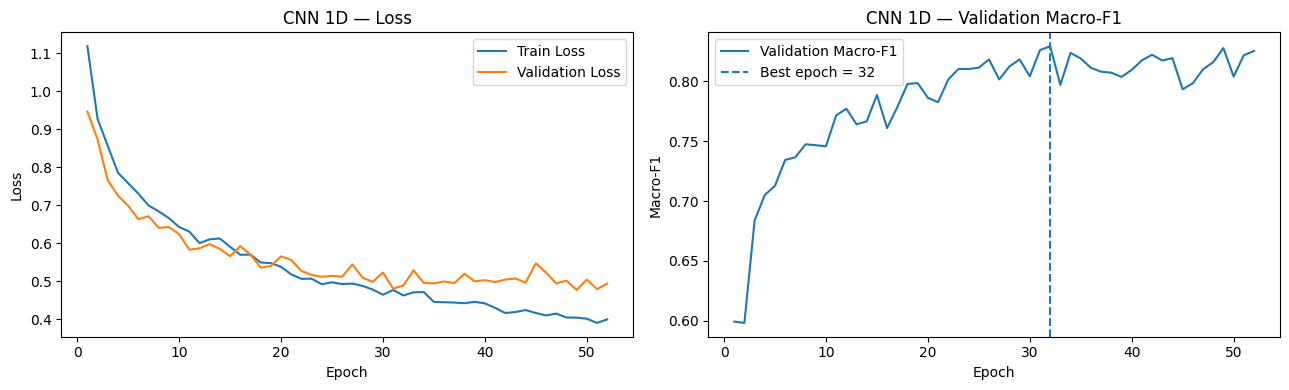

In [ ]:
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df['epoch'], history_df['train_loss'], label='Train Loss')
axes[0].plot(history_df['epoch'], history_df['val_loss'], label='Validation Loss')
axes[0].set_title('CNN 1D — Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history_df['epoch'], history_df['val_macro_f1'], label='Validation Macro-F1')
axes[1].axvline(best_epoch, linestyle='--', label=f'Best epoch = {best_epoch}')
axes[1].set_title('CNN 1D — Validation Macro-F1')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Macro-F1')
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Evaluasi Final pada Test Set

In [ ]:
test_loss, test_macro_f1, y_test_true, y_test_pred = run_evaluation(model, test_loader, criterion)

cnn_metrics = {
    'Model': 'CNN 1D',
    'Accuracy': accuracy_score(y_test_true, y_test_pred),
    'Macro Precision': precision_score(y_test_true, y_test_pred, average='macro', zero_division=0),
    'Macro Recall': recall_score(y_test_true, y_test_pred, average='macro', zero_division=0),
    'Macro F1': f1_score(y_test_true, y_test_pred, average='macro', zero_division=0),
    'Balanced Accuracy': balanced_accuracy_score(y_test_true, y_test_pred),
    'Loss': test_loss,
}

print('=== Classification Report — CNN 1D (Test Set) ===')
print(classification_report(
    y_test_true,
    y_test_pred,
    labels=[0, 1, 2, 3],
    target_names=CLASS_NAMES,
    zero_division=0,
))

pd.DataFrame([cnn_metrics]).set_index('Model').round(4)

=== Classification Report — CNN 1D (Test Set) ===
                            precision    recall  f1-score   support

Sehat / Tidak Ada Indikasi       0.81      0.78      0.79       315
Jantung dan Pembuluh Darah       0.75      0.84      0.79       225
      Spes. Penyakit Dalam       0.84      0.72      0.78       300
           Spes. Paru-Paru       0.84      0.94      0.89       225

                  accuracy                           0.81      1065
                 macro avg       0.81      0.82      0.81      1065
              weighted avg       0.81      0.81      0.81      1065



,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy,Loss
Model,,,,,,
CNN 1D,0.8103,0.8104,0.8211,0.8131,0.8211,0.5087


### Confusion Matrix — CNN 1D

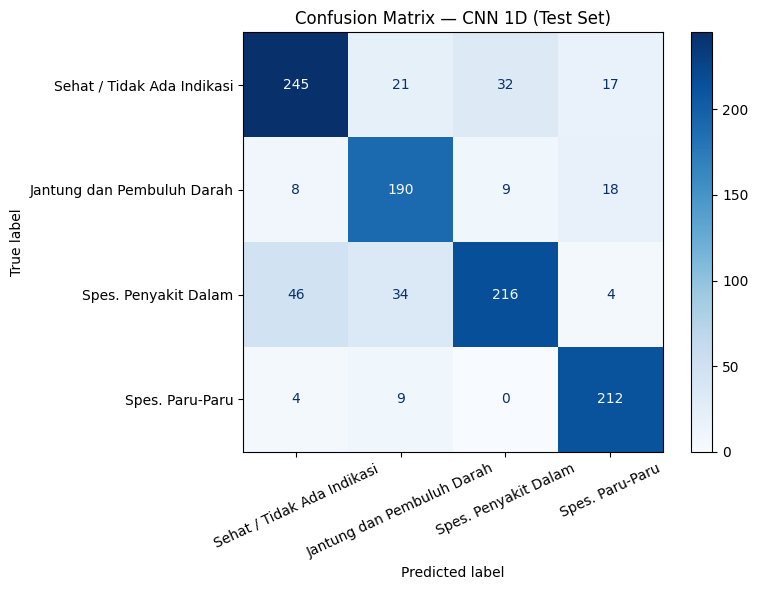

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_true,
    y_test_pred,
    labels=[0, 1, 2, 3],
    display_labels=CLASS_NAMES,
    cmap='Blues',
    xticks_rotation=25,
    ax=ax,
)
plt.title('Confusion Matrix — CNN 1D (Test Set)')
plt.tight_layout()
plt.show()

## 10. Perbandingan CNN 1D dengan Hasil Conformer

In [ ]:
# Referensi ini diambil dari output yang tercatat pada notebook utama:
# Data Engineer/Models/SHAP_XAI_conformer_v2.ipynb.
# Jika Conformer dilatih ulang atau dataset berubah, perbarui angka ini dari hasil eksperimen terbaru.
conformer_reference = {
    'Model': 'Tabular Conformer (hasil tercatat)',
    'Accuracy': 0.8948,
    'Macro Precision': 0.8912,
    'Macro Recall': 0.8974,
    'Macro F1': 0.8934,
    'Balanced Accuracy': 0.8974,
    'Loss': 0.2954,
}

comparison_df = pd.DataFrame([conformer_reference, cnn_metrics]).set_index('Model')
comparison_df.round(4)

# Export supaya mudah dimasukkan ke tabel hasil penelitian.
comparison_df.to_csv('comparison_conformer_vs_cnn1d.csv')
print('Tabel disimpan ke comparison_conformer_vs_cnn1d.csv')

,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy,Loss
Model,,,,,,
Tabular Conformer (hasil tercatat),0.8948,0.8912,0.8974,0.8934,0.8974,0.2954
CNN 1D,0.8103,0.8104,0.8211,0.8131,0.8211,0.5087


Tabel disimpan ke comparison_conformer_vs_cnn1d.csv


## 11. Simpan Model CNN dan Scaler

In [ ]:
import joblib
import json

# Simpan state_dict model (bukan seluruh objek model).
torch.save(model.state_dict(), 'cnn1d_tabular_best.pth')
joblib.dump(scaler, 'scaler_cnn1d.pkl')

config_cnn = {
    'model_name': 'CNN1D',
    'input_features': FEATURES,
    'n_classes': 4,
    'class_names': CLASS_NAMES,
    'best_epoch': int(best_epoch),
    'best_validation_macro_f1': float(best_val_f1),
    'seed': SEED,
    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,
    'weight_decay': WEIGHT_DECAY,
}
with open('cnn1d_config.json', 'w', encoding='utf-8') as f:
    json.dump(config_cnn, f, ensure_ascii=False, indent=2)

print('Artefak disimpan: cnn1d_tabular_best.pth, scaler_cnn1d.pkl, cnn1d_config.json')

Artefak disimpan: cnn1d_tabular_best.pth, scaler_cnn1d.pkl, cnn1d_config.json


## Catatan Interpretasi

- Bandingkan terutama **Macro-F1** dan **Balanced Accuracy**, selain accuracy, karena keduanya memperlihatkan performa lintas kelas.
- Nilai Conformer pada tabel di atas merupakan angka referensi dari output yang sebelumnya tercatat; nilai CNN dihitung saat notebook ini dijalankan. Pastikan versi dataset, seed, split, dan kode Conformer tetap sama sebelum menyimpulkan perbedaan.
- Karena CNN 1D menerima fitur tabular sebagai urutan, hasilnya dipengaruhi urutan fitur yang ditentukan. Pertahankan urutan `FEATURES` ini ketika menjalankan eksperimen.
- Angka evaluasi tetap menggambarkan dataset hasil balancing Plan B, bukan otomatis kinerja pada distribusi pasien asli.